## IMPORTS AND DB

In [26]:
import pandas as pd
import ast
import re
from collections import defaultdict
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("songs_with_genres_final.csv")

## DATA CLEANING AND SCALING

In [27]:
def ensure_list(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]
    return x

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

df['artists'] = df['artists'].apply(ensure_list)
df['name_clean'] = df['name'].str.strip().str.lower()


In [28]:
df['genre_list'] = df['genres_filtered'].fillna('').apply(
    lambda x: [g.strip() for g in x.split(',') if g]
)

mlb = MultiLabelBinarizer()
genre_matrix = mlb.fit_transform(df['genre_list'])
genre_df = pd.DataFrame(genre_matrix, columns=mlb.classes_) * 0.5

df = pd.concat([df, genre_df], axis=1)

In [29]:
base_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'popularity'
]

features = base_features + list(genre_df.columns)

df[features] = df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features]).astype('float32')


## COSINE SIMILARITY

In [63]:
def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None

def has_common_artist(a, b):
    return len(set(a) & set(b)) > 0

COLLAB_WEIGHT = 0.15
SAME_ARTIST_PENALTY = 0.1

In [38]:
def recommend_songs_indices(song_name, artist_name=None, num_recommendations=5):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return []

    idx = matches.sort_values(by='popularity', ascending=False).index[0]

    # similarity
    query_vec = X_scaled[idx].reshape(1, -1)
    similarities = cosine_similarity(query_vec, X_scaled)[0]

    # artist logic
    input_artists = df.loc[idx, 'artists']
    main_artist = get_main_artist(input_artists)

    same_artist = df['artists'].apply(
        lambda x: main_artist in x if main_artist else False
    ).astype(int)

    same_artist_penalty = same_artist * SAME_ARTIST_PENALTY

    collab_bonus = df['artists'].apply(
        lambda x: has_common_artist(x, input_artists)
    ).astype(int) * COLLAB_WEIGHT

    final_scores = similarities + collab_bonus - same_artist_penalty

    final_scores[idx] = -1

    sorted_indices = final_scores.argsort()[::-1]

    seen_tracks = set()
    artist_count = defaultdict(int)
    top_indices = []

    for idx_candidate in sorted_indices:
        name = normalize_name(df.loc[idx_candidate, 'name'])
        artist = get_main_artist(df.loc[idx_candidate, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        if key in seen_tracks:
            continue

        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        top_indices.append(idx_candidate)

        if len(top_indices) >= num_recommendations:
            break

    return idx, top_indices

## KNN

In [39]:
knn = NearestNeighbors(
    n_neighbors=20,        
    metric='euclidean',
    algorithm='brute'
)

knn.fit(X_scaled)

print("KNN model ready")

KNN model ready


In [64]:
def get_song_index(song_name, artist_name=None):

    song_name_clean = song_name.strip().lower()

    matches = df[df['name_clean'] == song_name_clean]

    if artist_name:
        matches = matches[matches['artists'].apply(
            lambda x: artist_name.lower() in [a.lower() for a in x]
        )]

    if matches.empty:
        print("Song not found")
        return None

    idx = matches.sort_values(by='popularity', ascending=False).index[0]
    return idx

In [66]:
from collections import defaultdict

def normalize_name(x):
    return x.lower().strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None


def recommend_knn_idx(idx, k=5):

    distances, indices = knn.kneighbors(
        X_scaled[idx].reshape(1, -1),
        n_neighbors=30   
    )

    indices = indices.flatten()

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in indices:

        if i == idx:
            continue

        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        if key in seen_tracks:
            continue

        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        results.append(i)

        if len(results) >= k:
            break

    return results

In [44]:
def recommend_knn_by_name(song_name, artist_name=None, k=5):

    idx = get_song_index(song_name, artist_name)
    if idx is None:
        return None, []

    recs = recommend_knn_idx(idx, k)
    return idx, recs

## KMeans

In [46]:
k = 50  

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df = df.copy()

df['cluster'] = kmeans.fit_predict(X_scaled)

print("KMeans clustering done")

KMeans clustering done


In [67]:
from collections import defaultdict
import re

def normalize_name(x):
    x = x.lower()
    x = re.sub(r'[^\w\s]', '', x)
    return x.strip()

def get_main_artist(lst):
    return lst[0] if isinstance(lst, list) and lst else None


def recommend_kmeans_idx(idx, k=5):

    cluster_id = df.loc[idx, 'cluster']
    cluster_songs = df[df['cluster'] == cluster_id]

    seen_tracks = set()
    artist_count = defaultdict(int)
    results = []

    for i in cluster_songs.index:

        if i == idx:
            continue

        name = normalize_name(df.loc[i, 'name'])
        artist = get_main_artist(df.loc[i, 'artists'])

        if artist is None:
            continue

        key = (name, artist)

        # remove duplicates
        if key in seen_tracks:
            continue

        # limit same artist
        if artist_count[artist] >= 2:
            continue

        seen_tracks.add(key)
        artist_count[artist] += 1
        results.append(i)

        if len(results) >= k:
            break

    if len(results) < k:
        for i in cluster_songs.index:
            if i == idx:
                continue
            if i not in results:
                results.append(i)
            if len(results) >= k:
                break

    return results

In [48]:
def recommend_kmeans_by_name(song_name, artist_name=None, k=5):

    idx = get_song_index(song_name, artist_name)
    if idx is None:
        return None, []

    recs = recommend_kmeans_idx(idx, k)
    return idx, recs

## GRAPHS

In [57]:
def compare_features_scaled(input_idx, rec_indices):

    feature_names = base_features
    feature_indices = list(range(len(base_features)))  

    input_vals = X_scaled[input_idx, feature_indices]
    plt.plot(feature_names, input_vals, marker='o', label='Input')

    for i, idx in enumerate(rec_indices):
        rec_vals = X_scaled[idx, feature_indices]
        plt.plot(feature_names, rec_vals, marker='o', alpha=0.7, label=f'Rec {i+1}')

    plt.xticks(rotation=45)
    plt.title("Scaled Audio Feature Comparison")
    plt.legend()

In [58]:
import seaborn as sns

def heatmap_compare_scaled(input_idx, rec_indices):

    indices = [input_idx] + list(rec_indices)
    labels = ["Input"] + [f"Rec {i+1}" for i in range(len(rec_indices))]

    feature_indices = list(range(len(base_features)))
    data = X_scaled[indices][:, feature_indices]
    sns.heatmap(data, yticklabels=labels, xticklabels=base_features, cmap="coolwarm")
    plt.title("Scaled Feature Heatmap")

In [68]:
def radar_compare_scaled(input_idx, rec_indices):

    import numpy as np

    features_to_plot = base_features[:6]
    feature_indices = [base_features.index(f) for f in features_to_plot]

    angles = np.linspace(0, 2*np.pi, len(features_to_plot), endpoint=False).tolist()
    angles += angles[:1]

    input_vals = X_scaled[input_idx, feature_indices].tolist()
    input_vals += input_vals[:1]

    plt.plot(angles, input_vals, linewidth=, label="Input")
    plt.fill(angles, input_vals, alpha=0.2)  

    for i, idx in enumerate(rec_indices):
        vals = X_scaled[idx, feature_indices].tolist()
        vals += vals[:1]

        plt.plot(angles, vals, linewidth=2, alpha=1, label=f"Rec {i+1}")
        plt.fill(angles, vals, alpha=0.1)  

    plt.xticks(angles[:-1], features_to_plot)
    plt.title("Scaled Radar Comparison (Filled)")
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

In [60]:
def compare_genres_models(input_idx, recs_kmeans, recs_knn, recs_cosine):

    def parse_genres(g):
        if isinstance(g, list):
            return g
        return [x.strip() for x in str(g).split(",") if x.strip()]

    def evaluate_model(name, rec_indices):
        print(f"\n===== {name} =====")

        input_genres = set(parse_genres(df.loc[input_idx, 'genres_filtered']))
        scores = []

        for i, idx in enumerate(rec_indices, 1):
            genres = set(parse_genres(df.loc[idx, 'genres_filtered']))

            common = input_genres & genres
            union = input_genres | genres

            jaccard = len(common) / len(union) if union else 0
            scores.append(jaccard)

            print(f"\n{name} Recommendation {i}")
            print(f"Name    : {df.loc[idx, 'name']}")
            print(f"Artist  : {', '.join(df.loc[idx, 'artists'])}")
            print(f"Genres  : {', '.join(genres)}")
            print(f"Common  : {', '.join(common)}")
            print(f"Jaccard : {round(jaccard, 3)}")

        avg_score = sum(scores) / len(scores) if scores else 0
        print(f"\n{name} Average Jaccard: {round(avg_score, 3)}")
        print("-" * 60)

        return avg_score

    # ---------- INPUT ----------
    print("\nINPUT SONG")
    print(f"Name   : {df.loc[input_idx, 'name']}")
    print(f"Artist : {', '.join(df.loc[input_idx, 'artists'])}")
    print(f"Genres : {', '.join(parse_genres(df.loc[input_idx, 'genres_filtered']))}")
    print("=" * 60)

    # ---------- MODELS ----------
    avg_kmeans = evaluate_model("KMeans", recs_kmeans)
    avg_knn = evaluate_model("KNN", recs_knn)
    avg_cosine = evaluate_model("Cosine", recs_cosine)

    # ---------- FINAL COMPARISON ----------
    print("\n===== FINAL COMPARISON =====")
    print(f"KMeans Avg Jaccard : {round(avg_kmeans, 3)}")
    print(f"KNN Avg Jaccard    : {round(avg_knn, 3)}")
    print(f"Cosine Avg Jaccard : {round(avg_cosine, 3)}")

    best = max([
        ("KMeans", avg_kmeans),
        ("KNN", avg_knn),
        ("Cosine", avg_cosine)
    ], key=lambda x: x[1])

    print(f"\nBest Genre Match Model: {best[0]} ({round(best[1], 3)})")

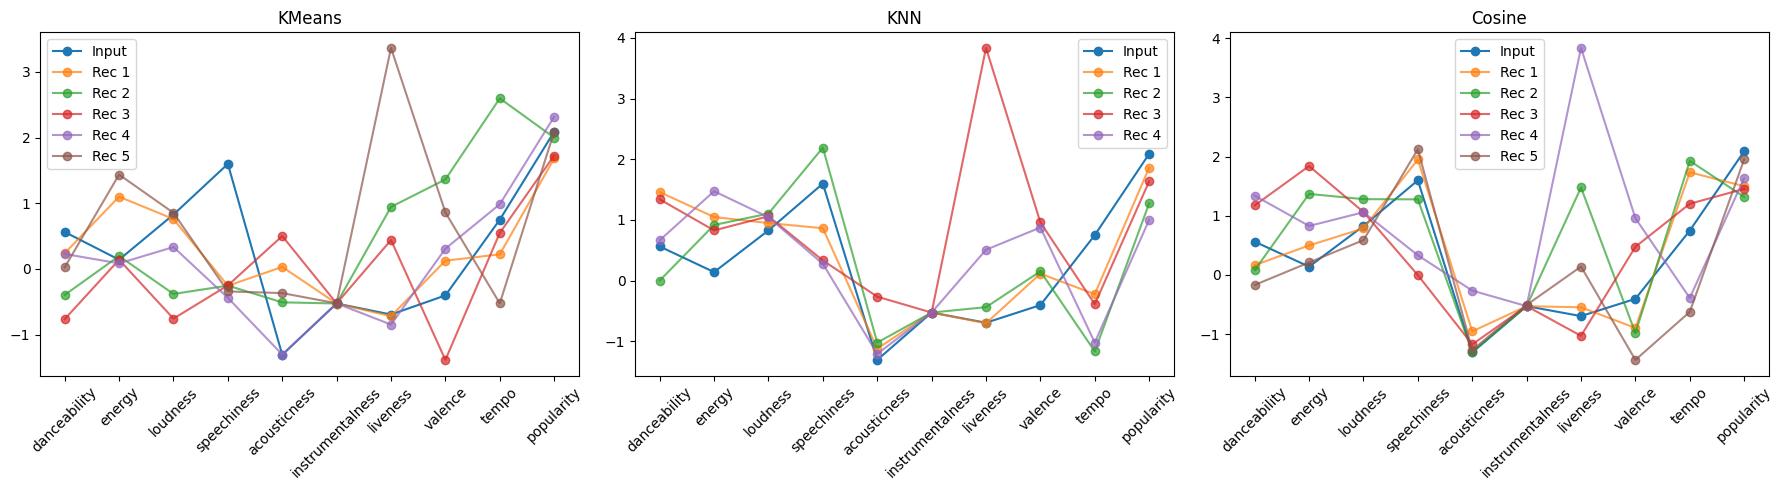

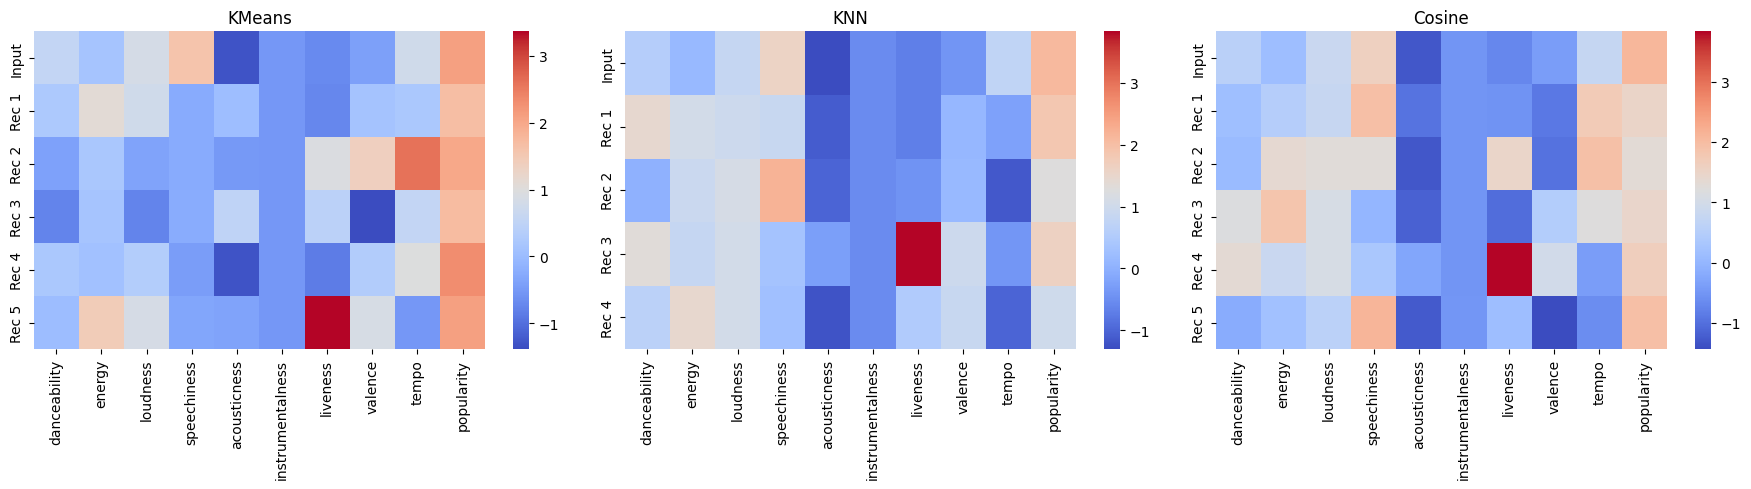

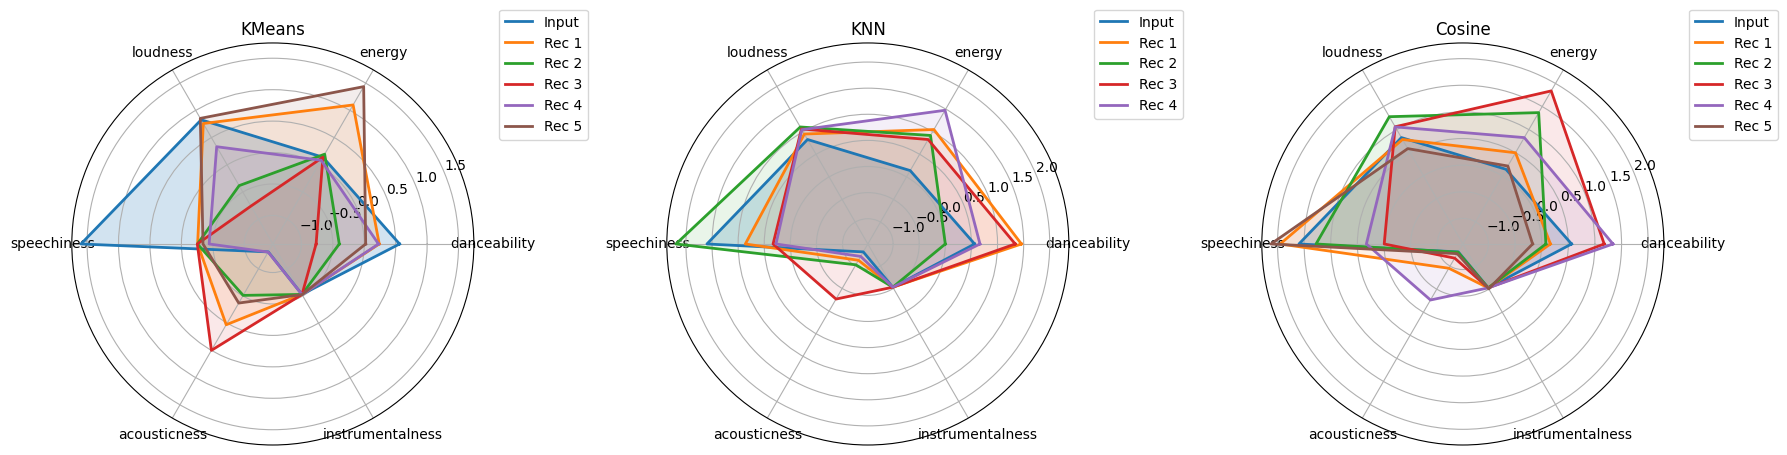


INPUT SONG
Name   : DNA.
Artist : Kendrick Lamar
Genres : conscious hip hop, hardcore hip hop, hip hop, political hip hop, trap, west coast hip hop

===== KMeans =====

KMeans Recommendation 1
Name    : Can't Take My Eyes off You
Artist  : Frankie Valli
Genres  : romantic, oldies, love, easy listening
Common  : 
Jaccard : 0.0

KMeans Recommendation 2
Name    : I Want You Back
Artist  : The Jackson 5
Genres  : disco, oldies, funk, motown, pop, soul
Common  : 
Jaccard : 0.0

KMeans Recommendation 3
Name    : I'm Not In Love
Artist  : 10cc
Genres  : soft rock, oldies, romantic, love, rock, classic rock, pop
Common  : 
Jaccard : 0.0

KMeans Recommendation 4
Name    : Hotel California - 2013 Remaster
Artist  : Eagles
Genres  : vocal, soft rock, pop rock, country rock, rock, reggae, sad, pop
Common  : 
Jaccard : 0.0

KMeans Recommendation 5
Name    : Dancing Queen
Artist  : ABBA
Genres  : disco, oldies, swedish, dance, pop
Common  : 
Jaccard : 0.0

KMeans Average Jaccard: 0.0
--------------

In [69]:
import matplotlib.pyplot as plt

# ---------- GET RECOMMENDATIONS ----------
idx, recs_knn = recommend_knn_by_name("DNA.", "Kendrick Lamar", 5)
_, recs_cosine = recommend_songs_indices("DNA.", "Kendrick Lamar", 5)
_, recs_kmeans = recommend_kmeans_by_name("DNA.", "Kendrick Lamar", 5)


# =========================================================
# 🔹 LINE PLOTS (SIDE-BY-SIDE)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plt.sca(axes[0])
compare_features_scaled(idx, recs_kmeans)
plt.title("KMeans")

plt.sca(axes[1])
compare_features_scaled(idx, recs_knn)
plt.title("KNN")

plt.sca(axes[2])
compare_features_scaled(idx, recs_cosine)
plt.title("Cosine")

plt.tight_layout()
plt.show()


# =========================================================
# 🔹 HEATMAPS (SIDE-BY-SIDE)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plt.sca(axes[0])
heatmap_compare_scaled(idx, recs_kmeans)
plt.title("KMeans")

plt.sca(axes[1])
heatmap_compare_scaled(idx, recs_knn)
plt.title("KNN")

plt.sca(axes[2])
heatmap_compare_scaled(idx, recs_cosine)
plt.title("Cosine")

plt.tight_layout()
plt.show()


# =========================================================
# 🔹 RADAR PLOTS (SIDE-BY-SIDE)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw=dict(polar=True))

plt.sca(axes[0])
radar_compare_scaled(idx, recs_kmeans)
plt.title("KMeans")

plt.sca(axes[1])
radar_compare_scaled(idx, recs_knn)
plt.title("KNN")

plt.sca(axes[2])
radar_compare_scaled(idx, recs_cosine)
plt.title("Cosine")

plt.tight_layout()
plt.show()


# =========================================================
# 🔹 GENRE COMPARISON (TEXT)
# =========================================================
compare_genres_models(idx, recs_kmeans, recs_knn, recs_cosine)